# Sesión 1 · Primeros pasos en Colab y Python
**Curso:** Uso de IA para el análisis descriptivo y predictivo en energías renovables

**Objetivo:** perder el miedo al cuaderno: ejecutar celdas, usar Python básico y ver por qué un modelo *aprende* en lugar de seguir reglas escritas a mano.

> Ejecute cada celda con `Shift + Enter`. Las celdas de texto (como esta) explican; las de código se ejecutan.

## 1. Su primera celda de código
Python puede ser una calculadora. Una turbina de 2 MW que opera al 35 % de su capacidad en un día:

In [2]:
capacidad_mw = 2
factor = 0.35
print('Energía en 24 h (MWh):', capacidad_mw * factor * 24)

Energía en 24 h (MWh): 16.799999999999997


## 2. Listas y funciones
Una **lista** guarda varios valores; una **función** guarda una receta reutilizable.

In [3]:
irradiancia = [0, 150, 420, 780, 910, 640, 120]   # W/m² a distintas horas
def promedio(valores):
    return sum(valores) / len(valores)
print('Promedio:', round(promedio(irradiancia), 1))

Promedio: 431.4


## 3. Una tabla con pandas
`pandas` organiza datos en filas y columnas, como una hoja de cálculo.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
estaciones = pd.DataFrame({'estacion': ['A','B','C','D'], 'tipo': ['solar','eolica','solar','eolica'], 'capacidad_mw': [5, 12, 8, 20]})
estaciones

,estacion,tipo,capacidad_mw
0,A,solar,5
1,B,eolica,12
2,C,solar,8
3,D,eolica,20


In [5]:
print(estaciones[estaciones['tipo'] == 'solar'])        # filtrar
print(estaciones.groupby('tipo')['capacidad_mw'].sum())  # agrupar

  estacion   tipo  capacidad_mw
0        A  solar             5
2        C  solar             8
tipo
eolica    32
solar     13
Name: capacidad_mw, dtype: int64


## 4. Línea de tiempo de la IA
Un gráfico sencillo con `matplotlib` para repasar la historia vista en clase.

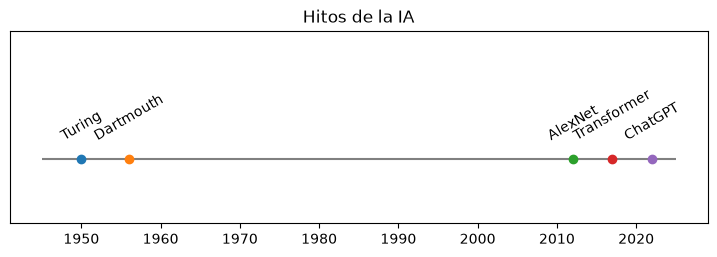

In [6]:
hitos = {1950: 'Turing', 1956: 'Dartmouth', 2012: 'AlexNet', 2017: 'Transformer', 2022: 'ChatGPT'}
plt.figure(figsize=(9, 2.5))
plt.hlines(0, 1945, 2025, color='gray')
for anio, nombre in hitos.items():
    plt.plot(anio, 0, 'o'); plt.text(anio, 0.15, nombre, ha='center', rotation=30)
plt.yticks([]); plt.ylim(-0.5, 1); plt.title('Hitos de la IA'); plt.show()

## 5. Regla escrita a mano vs. modelo que aprende
Problema: estimar la generación (kW) de un panel a partir de la irradiancia.
- **Regla a mano:** "si irradiancia > 500 genera 300, si no genera 100".
- **Modelo:** aprende la relación a partir de ejemplos.

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
rng = np.random.default_rng(0)
irr = rng.uniform(0, 1000, 300)
gen = 0.3*irr + rng.normal(0, 15, 300)
regla = np.where(irr > 500, 300, 100)
modelo = LinearRegression().fit(irr.reshape(-1, 1), gen)
pred = modelo.predict(irr.reshape(-1, 1))
print('Error de la regla (MAE):', round(mean_absolute_error(gen, regla), 1))
print('Error del modelo (MAE):', round(mean_absolute_error(gen, pred), 1))

Error de la regla (MAE): 58.3
Error del modelo (MAE): 11.5


El modelo se equivoca bastante menos: **aprendió** de los datos. Ese es el corazón del *machine learning*.

## Ejercicios
1. Cambie el umbral de la regla (500) y vea si logra igualar al modelo.
2. Agregue una estación E eólica de 15 MW a la tabla y repita el `groupby`.
3. Pida a un asistente de IA que le explique qué hace `LinearRegression` en dos frases.